# CNN-Based Chest X-Ray Pneumonia Classification

**Dataset:** Kaggle Chest X-Ray Images (Pneumonia)  
**Link:** https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia

> **Important:** The supplied dataset contains **NORMAL** and **PNEUMONIA** images. Therefore this notebook evaluates pneumonia classification, not heart-disease diagnosis, despite the assignment wording.

This notebook covers data acquisition, exploration, HOG/LBP/GLCM feature extraction, 70/15/15 stratified splitting, CNN training, 3-fold cross-validation for lightweight hyperparameter tuning, Accuracy/Precision/Recall/F1/AUROC, confusion matrix, ROC curve, misclassification analysis, and an optional handcrafted-feature comparison.


In [ ]:
# Install once if necessary:
# %pip install -q kagglehub tensorflow scikit-image scikit-learn seaborn pandas matplotlib pillow

import random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve
from sklearn.utils.class_weight import compute_class_weight
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED=42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
warnings.filterwarnings("ignore")
print("TensorFlow:",tf.__version__)
print("GPU:",tf.config.list_physical_devices("GPU"))


TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Task 1 — Data Acquisition and Exploration

In [2]:
import kagglehub

DATASET_ID="paultimothymooney/chest-xray-pneumonia"
DATASET_PATH=Path(kagglehub.dataset_download(DATASET_ID))
DATA_ROOT=DATASET_PATH/"chest_xray" if (DATASET_PATH/"chest_xray").exists() else DATASET_PATH
print("Dataset:",DATA_ROOT)


Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset: /kaggle/input/chest-xray-pneumonia/chest_xray


In [3]:
EXT={".jpg",".jpeg",".png",".bmp"}
rows=[]
for p in DATA_ROOT.rglob("*"):
    if p.is_file() and p.suffix.lower() in EXT and p.parent.name.upper() in {"NORMAL","PNEUMONIA"}:
        rows.append({"path":str(p),"label":p.parent.name.upper()})
df=pd.DataFrame(rows)
print("Usable images:",len(df))
print(df["label"].value_counts())


Usable images: 17568
label
PNEUMONIA    12819
NORMAL        4749
Name: count, dtype: int64


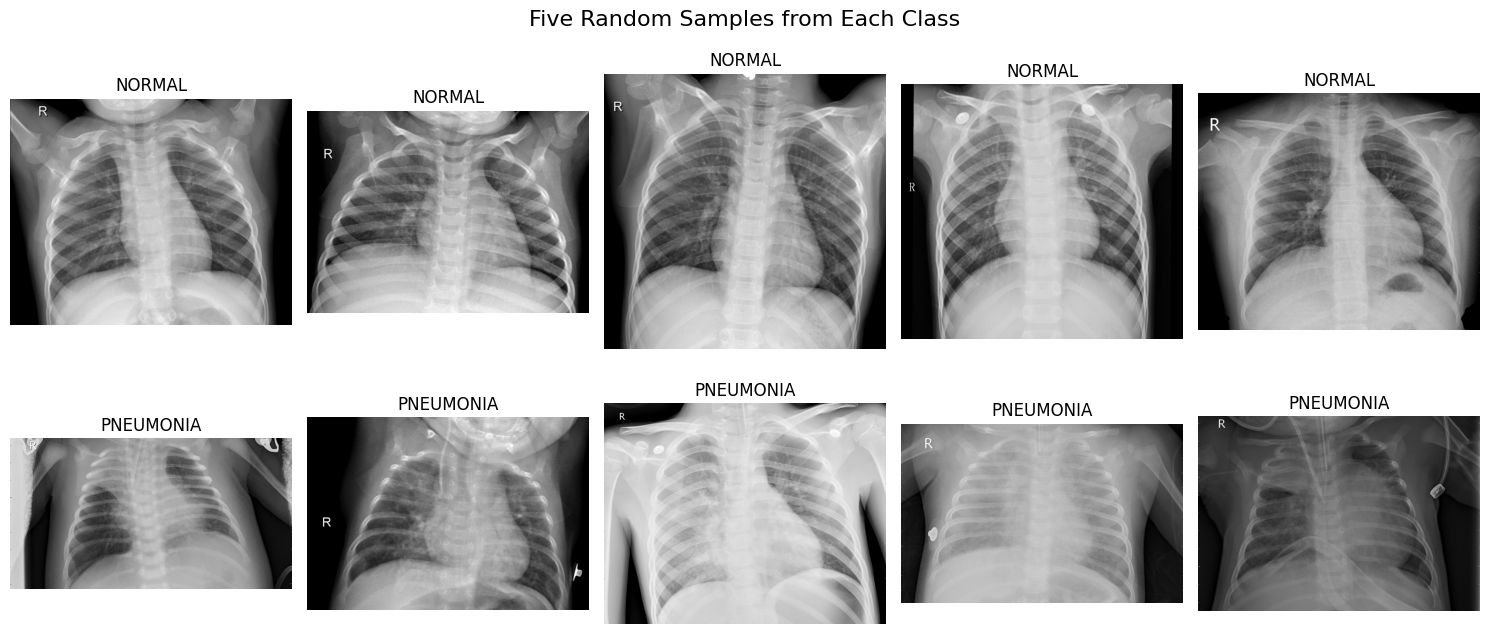

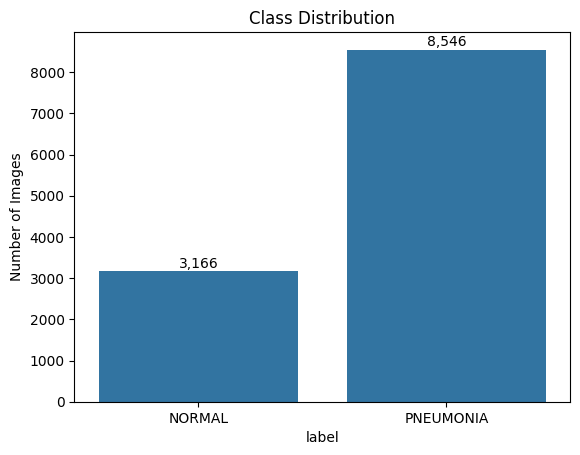

Class proportions:
label
NORMAL       0.2703
PNEUMONIA    0.7297
Name: count, dtype: float64


In [4]:
df = df[~df['path'].str.contains('/__MACOSX/', na=False)]

fig,axes=plt.subplots(2,5,figsize=(15,7))
for r,cls in enumerate([
    "NORMAL",
    "PNEUMONIA"
]):
    s=df[df.label==cls].sample(5,random_state=SEED)
    for c,(_,row) in enumerate(s.iterrows()):
        axes[r,c].imshow(Image.open(row.path).convert("L"),cmap="gray")
        axes[r,c].set_title(cls); axes[r,c].axis("off")
plt.suptitle("Five Random Samples from Each Class",fontsize=16)
plt.tight_layout(); plt.show()

counts=df.label.value_counts().reindex(["NORMAL","PNEUMONIA"])
ax=sns.barplot(x=counts.index,y=counts.values)
plt.title("Class Distribution"); plt.ylabel("Number of Images")
for i,v in enumerate(counts): ax.text(i,v+counts.max()*.01,f"{v:,}",ha="center")
plt.show()
print("Class proportions:")
print((counts/counts.sum()).round(4))

## 2. Task 2 — Preprocessing

Shape: (128, 128) Range: 0 - 221


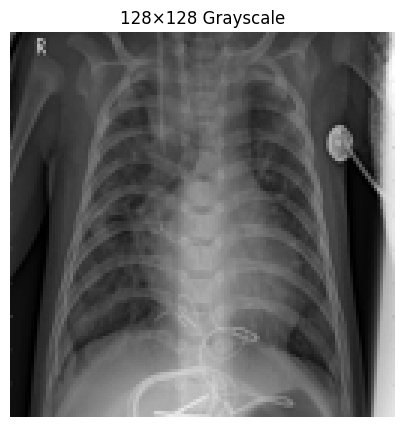

In [5]:
IMG_SIZE=(128,128)

def load_gray(path):
    return np.asarray(Image.open(path).convert("L").resize(IMG_SIZE),dtype=np.uint8)

sample=load_gray(df.iloc[0].path)
print("Shape:",sample.shape,"Range:",sample.min(),"-",sample.max())
plt.figure(figsize=(5,5)); plt.imshow(sample,cmap="gray"); plt.title("128×128 Grayscale"); plt.axis("off"); plt.show()


### HOG

In [6]:
def hog_features(img):
    return hog(img,orientations=9,pixels_per_cell=(16,16),cells_per_block=(2,2),block_norm="L2-Hys")

print("HOG length:",len(hog_features(sample)))


HOG length: 1764


### LBP

In [7]:
def lbp_features(img,radius=2,points=16):
    lbp=local_binary_pattern(img,points,radius,method="uniform")
    bins=points+2
    hist,_=np.histogram(lbp.ravel(),bins=np.arange(bins+1),range=(0,bins))
    hist=hist.astype(np.float32)
    return hist/(hist.sum()+1e-8)

print("LBP length:",len(lbp_features(sample)))


LBP length: 18


### GLCM

In [8]:
def glcm_features(img):
    q=(img//8).astype(np.uint8)
    g=graycomatrix(q,distances=[1,2],angles=[0,np.pi/4,np.pi/2,3*np.pi/4],
                   levels=32,symmetric=True,normed=True)
    props=["contrast","dissimilarity","homogeneity","energy","correlation","ASM"]
    out=[]
    for p in props:
        z=graycoprops(g,p); out.extend([z.mean(),z.std()])
    return np.asarray(out,dtype=np.float32)

print("GLCM length:",len(glcm_features(sample)))


GLCM length: 12


In [9]:
def all_features(path):
    x=load_gray(path)
    return np.concatenate([hog_features(x),lbp_features(x),glcm_features(x)]).astype(np.float32)

feature_map={}
for i,row in enumerate(df.itertuples(index=False),1):
    try: feature_map[row.path]=all_features(row.path)
    except Exception as e: print("Skipped:",row.path,e)

X_features=np.vstack(list(feature_map.values()))
print("HOG+LBP+GLCM matrix:",X_features.shape)


HOG+LBP+GLCM matrix: (11712, 1794)


## 3. Stratified 70% / 15% / 15% Split

In [10]:
train_df,temp_df=train_test_split(df,test_size=.30,stratify=df.label,random_state=SEED)
val_df,test_df=train_test_split(temp_df,test_size=.50,stratify=temp_df.label,random_state=SEED)

for name,part in [("Train",train_df),("Validation",val_df),("Test",test_df)]:
    print(name,len(part),f"({len(part)/len(df):.1%})",part.label.value_counts().to_dict())


Train 8198 (70.0%) {'PNEUMONIA': 5982, 'NORMAL': 2216}
Validation 1757 (15.0%) {'PNEUMONIA': 1282, 'NORMAL': 475}
Test 1757 (15.0%) {'PNEUMONIA': 1282, 'NORMAL': 475}


In [11]:
def dataframe_to_images(data):
    X=np.empty((len(data),128,128,1),dtype=np.float32)
    y=np.empty(len(data),dtype=np.int32)
    for i,row in enumerate(data.itertuples(index=False)):
        X[i,:,:,0]=load_gray(row.path)/255.0
        y[i]=int(row.label=="PNEUMONIA")
    return X,y

X_train,y_train=dataframe_to_images(train_df)
X_val,y_val=dataframe_to_images(val_df)
X_test,y_test=dataframe_to_images(test_df)

cls=np.unique(y_train)
weights=compute_class_weight("balanced",classes=cls,y=y_train)
CLASS_WEIGHTS=dict(zip(cls,weights))
print(X_train.shape,X_val.shape,X_test.shape)
print("Class weights:",CLASS_WEIGHTS)


(8198, 128, 128, 1) (1757, 128, 128, 1) (1757, 128, 128, 1)
Class weights: {np.int32(0): np.float64(1.8497292418772564), np.int32(1): np.float64(0.6852223336676697)}


## 4. CNN Baseline

In [12]:
def build_cnn(lr=1e-3,dropout=.4):
    model=keras.Sequential([
        layers.Input((128,128,1)),
        layers.Conv2D(32,3,padding="same",activation="relu"),layers.BatchNormalization(),layers.MaxPooling2D(),
        layers.Conv2D(64,3,padding="same",activation="relu"),layers.BatchNormalization(),layers.MaxPooling2D(),
        layers.Conv2D(128,3,padding="same",activation="relu"),layers.BatchNormalization(),layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),layers.Dropout(dropout),
        layers.Dense(64,activation="relu"),layers.Dropout(dropout/2),
        layers.Dense(1,activation="sigmoid")
    ])
    model.compile(optimizer=keras.optimizers.Adam(lr),loss="binary_crossentropy",
                  metrics=[keras.metrics.BinaryAccuracy(name="accuracy"),
                           keras.metrics.Precision(name="precision"),
                           keras.metrics.Recall(name="recall"),keras.metrics.AUC(name="auc")])
    return model

augmentation=keras.Sequential([layers.RandomFlip("horizontal"),layers.RandomRotation(.04),layers.RandomZoom(.08)])

def train_dataset(X,y,batch=32):
    ds=tf.data.Dataset.from_tensor_slices((X,y)).shuffle(len(X),seed=SEED).batch(batch)
    return ds.map(lambda a,b:(augmentation(a,training=True),b),num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

def eval_dataset(X,y,batch=32):
    return tf.data.Dataset.from_tensor_slices((X,y)).batch(batch).prefetch(tf.data.AUTOTUNE)


In [13]:
baseline=build_cnn()
baseline.summary()

history=baseline.fit(
    train_dataset(X_train,y_train),
    validation_data=eval_dataset(X_val,y_val),
    epochs=15,class_weight=CLASS_WEIGHTS,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_auc",mode="max",patience=4,restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_auc",mode="max",factor=.5,patience=2,min_lr=1e-6)
    ]
)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,889 (398.00 KB)

 Trainable params: 101,441 (396.25 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 28s 74ms/step - accuracy: 0.8323 - auc: 0.9164 - loss: 0.3628 - precision: 0.9541 - recall: 0.8091 - val_accuracy: 0.7297 - val_auc: 0.5660 - val_loss: 1.5236 - val_precision: 0.7297 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.8683 - auc: 0.9470 - loss: 0.2935 - precision: 0.9602 - recall: 0.8549 - val_accuracy: 0.7297 - val_auc: 0.6355 - val_loss: 1.6866 - val_precision: 0.7297 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 11s 43ms/step - accuracy: 0.8974 - auc: 0.9621 - loss: 0.2492 - precision: 0.9671 - recall: 0.8897 - val_accuracy: 0.9306 - val_auc: 0.9772 - val_loss: 0.2012 - val_precision: 0.9322 - val_recall: 0.9758 - learning_rate: 0.0010
Epoch 4/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - accuracy: 0.9110 - auc: 0.9703 - loss: 0.2202 - precision: 0.9696 - recall: 0.9064 - val_accuracy: 0.7962 - val_auc: 0.9497 - val_loss: 0.40

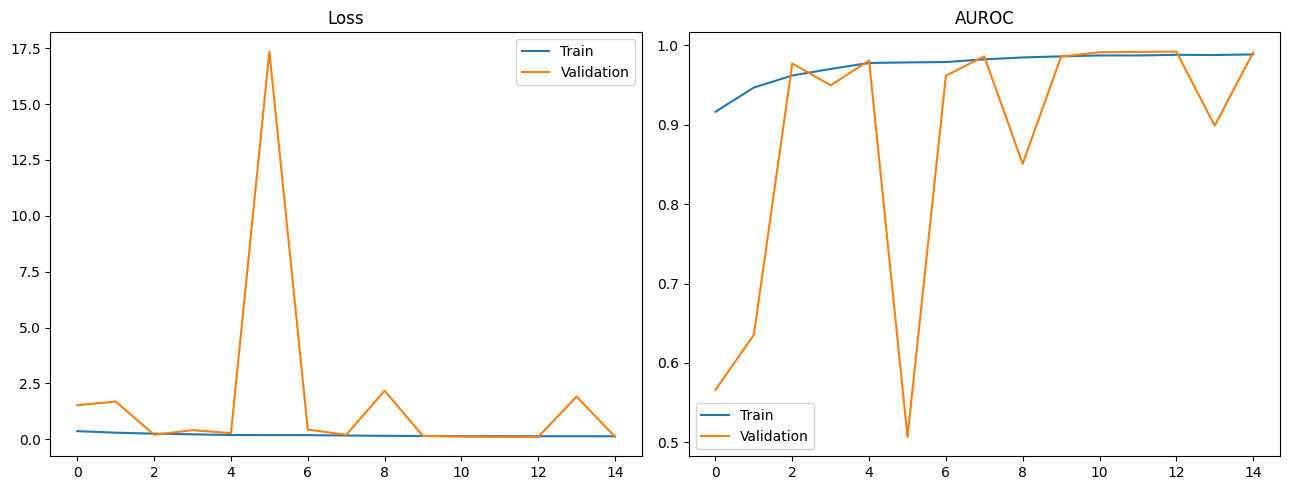

In [14]:
h=pd.DataFrame(history.history)
fig,ax=plt.subplots(1,2,figsize=(13,5))
ax[0].plot(h.loss,label="Train"); ax[0].plot(h.val_loss,label="Validation"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(h.auc,label="Train"); ax[1].plot(h.val_auc,label="Validation"); ax[1].set_title("AUROC"); ax[1].legend()
plt.tight_layout(); plt.show()


## 5. Evaluation — Accuracy, Precision, Recall, F1 and AUROC

In [15]:
def evaluate(model,X,y,name="Test"):
    prob=model.predict(X,batch_size=32,verbose=0).ravel()
    pred=(prob>=.5).astype(int)
    metrics={
        "Accuracy":accuracy_score(y,pred),
        "Precision":precision_score(y,pred,zero_division=0),
        "Recall":recall_score(y,pred,zero_division=0),
        "F1-score":f1_score(y,pred,zero_division=0),
        "AUROC":roc_auc_score(y,prob)
    }
    print("===",name,"===")
    for k,v in metrics.items(): print(f"{k:10s}: {v:.4f}")
    print(classification_report(y,pred,target_names=["NORMAL","PNEUMONIA"],zero_division=0))
    return metrics,prob,pred

baseline_metrics,baseline_prob,baseline_pred=evaluate(baseline,X_test,y_test,"Baseline CNN — Test")


=== Baseline CNN — Test ===
Accuracy  : 0.9613
Precision : 0.9817
Recall    : 0.9649
F1-score  : 0.9732
AUROC     : 0.9922
              precision    recall  f1-score   support

      NORMAL       0.91      0.95      0.93       475
   PNEUMONIA       0.98      0.96      0.97      1282

    accuracy                           0.96      1757
   macro avg       0.95      0.96      0.95      1757
weighted avg       0.96      0.96      0.96      1757



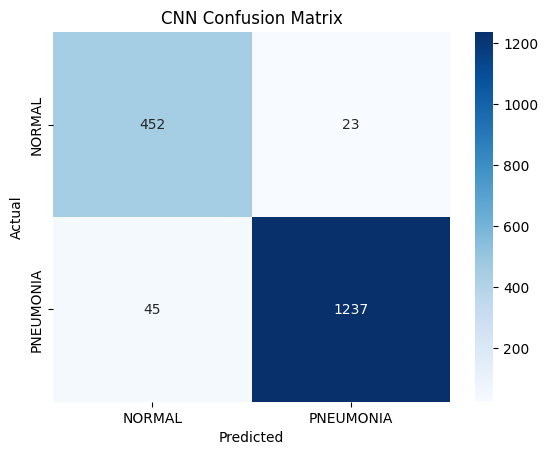

TN: 452 FP: 23 FN: 45 TP: 1237
False positive = normal predicted as pneumonia.
False negative = pneumonia predicted as normal; this is especially important in a screening context.


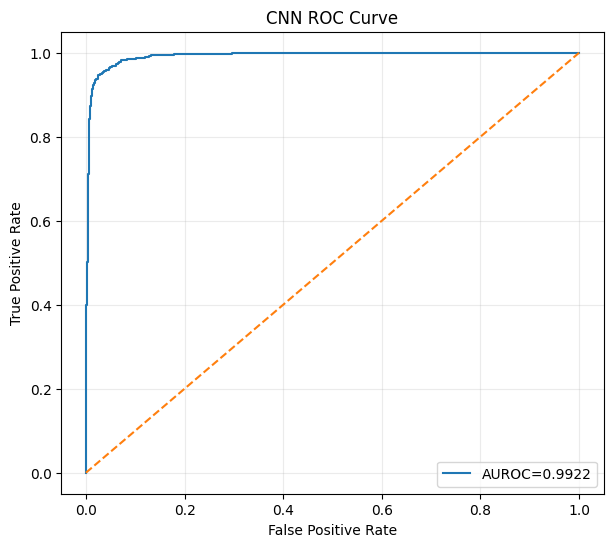

In [16]:
cm=confusion_matrix(y_test,baseline_pred)
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",
            xticklabels=["NORMAL","PNEUMONIA"],yticklabels=["NORMAL","PNEUMONIA"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("CNN Confusion Matrix"); plt.show()
tn,fp,fn,tp=cm.ravel()
print("TN:",tn,"FP:",fp,"FN:",fn,"TP:",tp)
print("False positive = normal predicted as pneumonia.")
print("False negative = pneumonia predicted as normal; this is especially important in a screening context.")

fpr,tpr,_=roc_curve(y_test,baseline_prob)
plt.figure(figsize=(7,6)); plt.plot(fpr,tpr,label=f"AUROC={roc_auc_score(y_test,baseline_prob):.4f}")
plt.plot([0,1],[0,1],"--"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("CNN ROC Curve"); plt.legend(); plt.grid(alpha=.25); plt.show()


## 6. Hyperparameter Tuning with 3-Fold Cross-Validation

Deep-learning k-fold cross-validation is computationally expensive. The following uses a configurable subset and short epoch budget. Increase the values for a more exhaustive run.

In [17]:
CV_FOLDS=3
CV_MAX_SAMPLES=1800       # None = all training images
CV_EPOCHS=5
LR_GRID=[1e-3,3e-4]
DROPOUT_GRID=[.30,.50]

rng=np.random.default_rng(SEED)
idx=np.arange(len(X_train))
if CV_MAX_SAMPLES is not None and len(idx)>CV_MAX_SAMPLES:
    idx=rng.choice(idx,CV_MAX_SAMPLES,replace=False)
X_cv,y_cv=X_train[idx],y_train[idx]
print("CV samples:",len(X_cv))


CV samples: 1800


In [18]:
def cv_run(X,y,lr,dropout):
    skf=StratifiedKFold(n_splits=CV_FOLDS,shuffle=True,random_state=SEED)
    results=[]
    for fold,(tr,va) in enumerate(skf.split(X,y),1):
        model=build_cnn(lr,dropout)
        c=np.unique(y[tr])
        w=compute_class_weight("balanced",classes=c,y=y[tr])
        model.fit(
            train_dataset(X[tr],y[tr]),validation_data=eval_dataset(X[va],y[va]),
            epochs=CV_EPOCHS,class_weight=dict(zip(c,w)),verbose=0,
            callbacks=[keras.callbacks.EarlyStopping(monitor="val_auc",mode="max",patience=2,restore_best_weights=True)]
        )
        p=model.predict(X[va],verbose=0).ravel(); q=(p>=.5).astype(int)
        results.append({
            "fold":fold,
            "accuracy":accuracy_score(y[va],q),
            "precision":precision_score(y[va],q,zero_division=0),
            "recall":recall_score(y[va],q,zero_division=0),
            "f1":f1_score(y[va],q,zero_division=0),
            "auroc":roc_auc_score(y[va],p)
        })
        tf.keras.backend.clear_session()
    return pd.DataFrame(results)

rows_cv=[]
for lr in LR_GRID:
    for dr in DROPOUT_GRID:
        print("Testing:",lr,dr)
        r=cv_run(X_cv,y_cv,lr,dr)
        rows_cv.append({
            "learning_rate":lr,"dropout":dr,
            "mean_accuracy":r.accuracy.mean(),
            "mean_precision":r.precision.mean(),
            "mean_recall":r.recall.mean(),
            "mean_f1":r.f1.mean(),
            "mean_auroc":r.auroc.mean(),
            "std_auroc":r.auroc.std()
        })

cv_summary=pd.DataFrame(rows_cv).sort_values("mean_auroc",ascending=False).reset_index(drop=True)
display(cv_summary.round(4))


Testing: 0.001 0.3
Testing: 0.001 0.5
Testing: 0.0003 0.3
Testing: 0.0003 0.5


,learning_rate,dropout,mean_accuracy,mean_precision,mean_recall,mean_f1,mean_auroc,std_auroc
0,0.0003,0.3,0.7144,0.7144,1.0,0.8334,0.8356,0.0596
1,0.0010,0.3,0.7144,0.7144,1.0,0.8334,0.7989,0.1359
2,0.0010,0.5,0.7144,0.7144,1.0,0.8334,0.7854,0.0879
3,0.0003,0.5,0.7144,0.7144,1.0,0.8334,0.7722,0.0279


In [19]:
best=cv_summary.iloc[0]
BEST_LR=float(best.learning_rate)
BEST_DROPOUT=float(best.dropout)
print("Selected learning rate:",BEST_LR)
print("Selected dropout:",BEST_DROPOUT)
print("Mean CV AUROC:",round(best.mean_auroc,4))


Selected learning rate: 0.0003
Selected dropout: 0.3
Mean CV AUROC: 0.8356


## 7. Final CNN and Held-Out Test Evaluation

In [20]:
final_model=build_cnn(BEST_LR,BEST_DROPOUT)
final_history=final_model.fit(
    train_dataset(X_train,y_train),validation_data=eval_dataset(X_val,y_val),
    epochs=20,class_weight=CLASS_WEIGHTS,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_auc",mode="max",patience=4,restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_auc",mode="max",factor=.5,patience=2,min_lr=1e-6)
    ]
)

final_metrics,final_prob,final_pred=evaluate(final_model,X_test,y_test,"Final CNN — Held-Out Test")
display(pd.DataFrame([final_metrics],index=["CNN"]).round(4))


Epoch 1/20
257/257 ━━━━━━━━━━━━━━━━━━━━ 24s 66ms/step - accuracy: 0.8195 - auc: 0.9071 - loss: 0.3843 - precision: 0.9498 - recall: 0.7946 - val_accuracy: 0.7297 - val_auc: 0.7154 - val_loss: 1.0241 - val_precision: 0.7297 - val_recall: 1.0000 - learning_rate: 3.0000e-04
Epoch 2/20
257/257 ━━━━━━━━━━━━━━━━━━━━ 11s 43ms/step - accuracy: 0.8722 - auc: 0.9467 - loss: 0.2923 - precision: 0.9622 - recall: 0.8586 - val_accuracy: 0.7336 - val_auc: 0.9308 - val_loss: 0.6809 - val_precision: 0.7326 - val_recall: 1.0000 - learning_rate: 3.0000e-04
Epoch 3/20
257/257 ━━━━━━━━━━━━━━━━━━━━ 11s 43ms/step - accuracy: 0.8946 - auc: 0.9620 - loss: 0.2491 - precision: 0.9678 - recall: 0.8850 - val_accuracy: 0.4974 - val_auc: 0.9710 - val_loss: 1.1590 - val_precision: 1.0000 - val_recall: 0.3112 - learning_rate: 3.0000e-04
Epoch 4/20
257/257 ━━━━━━━━━━━━━━━━━━━━ 11s 44ms/step - accuracy: 0.9030 - auc: 0.9674 - loss: 0.2307 - precision: 0.9691 - recall: 0.8957 - val_accuracy: 0.9368 - val_auc: 0.9786 - va

,Accuracy,Precision,Recall,F1-score,AUROC
CNN,0.9175,0.9018,0.9953,0.9462,0.9876


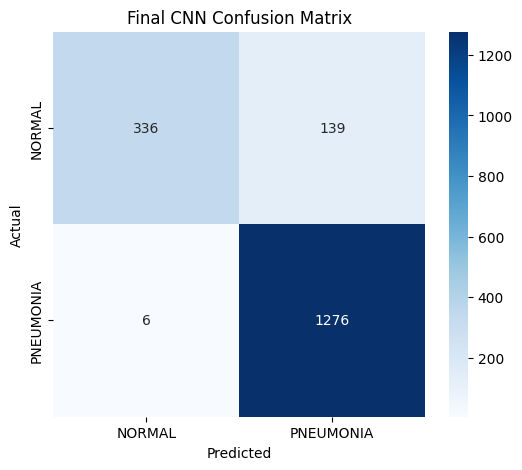

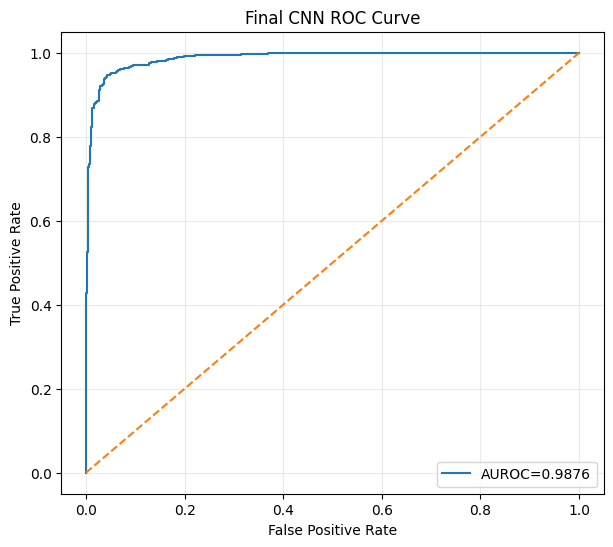

In [21]:
cm=confusion_matrix(y_test,final_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",
            xticklabels=["NORMAL","PNEUMONIA"],yticklabels=["NORMAL","PNEUMONIA"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Final CNN Confusion Matrix"); plt.show()

fpr,tpr,_=roc_curve(y_test,final_prob)
plt.figure(figsize=(7,6))
plt.plot(fpr,tpr,label=f"AUROC={roc_auc_score(y_test,final_prob):.4f}")
plt.plot([0,1],[0,1],"--"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Final CNN ROC Curve"); plt.legend(); plt.grid(alpha=.25); plt.show()


## 8. Optional Comparison — HOG + LBP + GLCM + Logistic Regression

In [22]:
def get_features(data):
    keep=data[data.path.isin(feature_map)]
    X=np.vstack([feature_map[p] for p in keep.path])
    y=(keep.label=="PNEUMONIA").astype(int).to_numpy()
    return X,y

Xtrf,ytrf=get_features(train_df)
Xtef,ytef=get_features(test_df)

handcrafted=Pipeline([
    ("scaler",StandardScaler()),
    ("classifier",LogisticRegression(max_iter=1000,class_weight="balanced",random_state=SEED))
])
handcrafted.fit(Xtrf,ytrf)
hp=handcrafted.predict_proba(Xtef)[:,1]
hq=(hp>=.5).astype(int)

hand_metrics={
    "Accuracy":accuracy_score(ytef,hq),
    "Precision":precision_score(ytef,hq,zero_division=0),
    "Recall":recall_score(ytef,hq,zero_division=0),
    "F1-score":f1_score(ytef,hq,zero_division=0),
    "AUROC":roc_auc_score(ytef,hp)
}
comparison=pd.DataFrame([final_metrics,hand_metrics],
                        index=["CNN","HOG + LBP + GLCM + Logistic Regression"])
display(comparison.round(4))


,Accuracy,Precision,Recall,F1-score,AUROC
CNN,0.9175,0.9018,0.9953,0.9462,0.9876
HOG + LBP + GLCM + Logistic Regression,0.9835,0.9898,0.9875,0.9887,0.9979


## 9. Discussion / Conclusion Guide

Use the actual values generated by the notebook in the final report.

1. **Data exploration:** report exact image counts and class imbalance.
2. **Preprocessing:** explain 128×128 resizing, grayscale conversion and normalization.
3. **HOG:** captures local edge/orientation structure.
4. **LBP:** captures local texture patterns.
5. **GLCM:** captures gray-level spatial relationships.
6. **CNN:** describe convolution, pooling, batch normalization, global average pooling, dropout, augmentation and class weighting.
7. **Cross-validation:** report selected learning rate/dropout and mean CV AUROC.
8. **Evaluation:** report Accuracy, Precision, Recall, F1-score, AUROC and the confusion matrix.
9. **Misclassification:** discuss false positives and false negatives separately. A false negative is a pneumonia case predicted as normal.
10. **Limitations:** this is an educational experiment, not a clinically validated diagnostic system. The supplied dataset is for pneumonia, not heart disease. Dataset bias and patient-level leakage should be considered; patient-level splitting is preferable when patient IDs are available.

**Do not invent numerical results before executing the notebook.**


In [23]:
# Save final artifacts
OUT=Path("outputs")
OUT.mkdir(exist_ok=True)
final_model.save(OUT/"pneumonia_cnn.keras")
comparison.to_csv(OUT/"model_comparison.csv")
print("Saved:",OUT/"pneumonia_cnn.keras")
print("Saved:",OUT/"model_comparison.csv")


Saved: outputs/pneumonia_cnn.keras
Saved: outputs/model_comparison.csv
